In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Lesson 6 — groupby() in Pandas

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")

tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
tips.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [4]:
tips["total_bill"].mean()

np.float64(19.78594262295082)

In [5]:
tips.groupby("day")["total_bill"].mean()

day
Thur    17.682742
Fri     17.151579
Sat     20.441379
Sun     21.410000
Name: total_bill, dtype: float64

In [6]:
tips.groupby("day")["total_bill"].mean().reset_index()

,day,total_bill
0,Thur,17.682742
1,Fri,17.151579
2,Sat,20.441379
3,Sun,21.410000


In [7]:
# एक दूसरा तरीका:as_index=False
tips.groupby("day", as_index=False)["total_bill"].mean()

,day,total_bill
0,Thur,17.682742
1,Fri,17.151579
2,Sat,20.441379
3,Sun,21.410000


In [8]:
# अब इसे एक variable में store करते हैं:
avg_bill_day = (tips.groupby("day", as_index=False)["total_bill"].mean())
avg_bill_day


,day,total_bill
0,Thur,17.682742
1,Fri,17.151579
2,Sat,20.441379
3,Sun,21.410000


In [9]:
avg_bill_day.sort_values(
    "total_bill",
    ascending=False
)

,day,total_bill
3,Sun,21.410000
2,Sat,20.441379
0,Thur,17.682742
1,Fri,17.151579


In [10]:
avg_bill_day.sort_values(
    "total_bill",
    ascending=False
).head(1)

,day,total_bill
3,Sun,21.41


In [11]:
# किस day पर total sales सबसे ज्यादा हुई?
tips.groupby("day")["total_bill"].sum()

day
Thur    1096.33
Fri      325.88
Sat     1778.40
Sun     1627.16
Name: total_bill, dtype: float64

In [12]:
# Total bill
tips.groupby("day")["total_bill"].sum()

day
Thur    1096.33
Fri      325.88
Sat     1778.40
Sun     1627.16
Name: total_bill, dtype: float64

In [13]:
# प्रत्येक day पर कितने transactions हुए?
tips.groupby("day")["total_bill"].count()

day
Thur    62
Fri     19
Sat     87
Sun     76
Name: total_bill, dtype: int64

In [14]:
# # size() vs count()

In [15]:
tips.groupby("day")["total_bill"].count() 
# यह selected column में non-null values count करता है।

day
Thur    62
Fri     19
Sat     87
Sun     76
Name: total_bill, dtype: int64

In [16]:
tips.groupby("day").size()

day
Thur    62
Fri     19
Sat     87
Sun     76
dtype: int64

In [17]:
tips.groupby("day")["total_bill"].median()

day
Thur    16.20
Fri     15.38
Sat     18.24
Sun     19.63
Name: total_bill, dtype: float64

In [18]:
# Multiple Aggregations

मान लो हमें day-wise:
Average bill
Maximum bill
Minimum bill
Total bill सब चाहिए।

In [19]:
tips.groupby("day")["total_bill"].agg(["mean", "max", "min", "sum"])

,mean,max,min,sum
day,,,,
Thur,17.682742,43.11,7.51,1096.33
Fri,17.151579,40.17,5.75,325.88
Sat,20.441379,50.81,3.07,1778.40
Sun,21.410000,48.17,7.25,1627.16


In [20]:
# Different columns पर Different Calculations
tips.groupby("day").agg({
    "total_bill": "mean",
    "tip": "mean",
    "size": "mean"})

,total_bill,tip,size
day,,,
Thur,17.682742,2.771452,2.451613
Fri,17.151579,2.734737,2.105263
Sat,20.441379,2.993103,2.517241
Sun,21.410000,3.255132,2.842105


In [21]:
# Multiple Aggregations per Column
tips.groupby("day").agg({
    "total_bill": ["mean", "max", "min"],
    "tip": ["mean", "max"]
})

total_bill                    tip       
           mean    max   min      mean    max
day                                          
Thur  17.682742  43.11  7.51  2.771452   6.70
Fri   17.151579  40.17  5.75  2.734737   4.73
Sat   20.441379  50.81  3.07  2.993103  10.00
Sun   21.410000  48.17  7.25  3.255132   6.50

In [22]:
tips.groupby("day").agg({
    "total_bill": ["mean", "max", "min"],
    "tip": ["mean", "max"]
})

total_bill                    tip       
           mean    max   min      mean    max
day                                          
Thur  17.682742  43.11  7.51  2.771452   6.70
Fri   17.151579  40.17  5.75  2.734737   4.73
Sat   20.441379  50.81  3.07  2.993103  10.00
Sun   21.410000  48.17  7.25  3.255132   6.50

In [23]:
# Average Tip by Gender
tips.groupby("sex")["tip"].mean()

sex
Male      3.089618
Female    2.833448
Name: tip, dtype: float64

In [24]:
# or As Dataframe
tips.groupby("sex", as_index=False)["tip"].mean()

,sex,tip
0,Male,3.089618
1,Female,2.833448


In [25]:
# Smoker vs Non-Smoker
# Smokers और non-smokers का average bill कितना है?

tips.groupby("smoker",as_index=False)["total_bill"].mean()

,smoker,total_bill
0,Yes,20.756344
1,No,19.188278


In [26]:
# total spending:
tips.groupby("smoker",as_index=False)["total_bill"].sum()

,smoker,total_bill
0,Yes,1930.34
1,No,2897.43


In [27]:
# किस day और meal time combination पर average bill कितना है?
tips.groupby(["day", "time"])["total_bill"].mean()

day   time  
Thur  Lunch     17.664754
      Dinner    18.780000
Fri   Lunch     12.845714
      Dinner    19.663333
Sat   Lunch           NaN
      Dinner    20.441379
Sun   Lunch           NaN
      Dinner    21.410000
Name: total_bill, dtype: float64

In [28]:
# Multiple Groups + Multiple Metrics
day_time_report = (tips.groupby(["day", "time"]).agg({
            "total_bill": ["mean", "sum"],
            "tip": "mean",
            "size": "mean"}))

day_time_report

total_bill                tip      size
                  mean      sum      mean      mean
day  time                                          
Thur Lunch   17.664754  1077.55  2.767705  2.459016
     Dinner  18.780000    18.78  3.000000  2.000000
Fri  Lunch   12.845714    89.92  2.382857  2.000000
     Dinner  19.663333   235.96  2.940000  2.166667
Sat  Lunch         NaN     0.00       NaN       NaN
     Dinner  20.441379  1778.40  2.993103  2.517241
Sun  Lunch         NaN     0.00       NaN       NaN
     Dinner  21.410000  1627.16  3.255132  2.842105

In [29]:
# Groupby + Sorting
# मान लो हमें day-wise total sales चाहिए और highest sales पहले चाहिए।

day_sales = (tips.groupby("day", as_index=False)["total_bill"].sum())
day_sales.sort_values("total_bill",ascending=False)

,day,total_bill
2,Sat,1778.40
3,Sun,1627.16
0,Thur,1096.33
1,Fri,325.88


In [30]:
# Groupby + Filter
# मान लो हमें केवल वे transactions चाहिए जिनका bill $20 से ज्यादा है।

high_bill = tips[tips["total_bill"] > 20]
high_bill.groupby("day")["total_bill"].mean() #finds daywise mean of bill

day
Thur    28.433125
Fri     27.111667
Sat     28.476579
Sun     28.582162
Name: total_bill, dtype: float64

In [31]:
# Groupby + Multiple Metrics — Practical Report
day_report = (
    tips.groupby("day")
        .agg(
            avg_bill=("total_bill", "mean"),
            total_sales=("total_bill", "sum"),
            avg_tip=("tip", "mean"),
            transactions=("total_bill", "count"),
            avg_party_size=("size", "mean")).reset_index())

day_report

,day,avg_bill,total_sales,avg_tip,transactions,avg_party_size
0,Thur,17.682742,1096.33,2.771452,62,2.451613
1,Fri,17.151579,325.88,2.734737,19,2.105263
2,Sat,20.441379,1778.40,2.993103,87,2.517241
3,Sun,21.410000,1627.16,3.255132,76,2.842105


In [32]:
day_report.sort_values("total_sales",ascending=False)

,day,avg_bill,total_sales,avg_tip,transactions,avg_party_size
2,Sat,20.441379,1778.40,2.993103,87,2.517241
3,Sun,21.410000,1627.16,3.255132,76,2.842105
0,Thur,17.682742,1096.33,2.771452,62,2.451613
1,Fri,17.151579,325.88,2.734737,19,2.105263


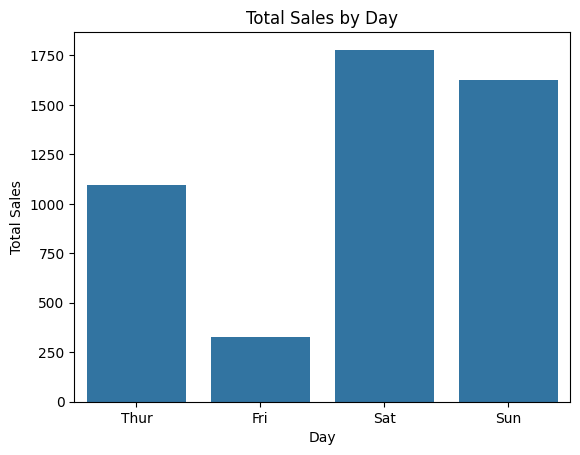

In [33]:
# अब एक बहुत important analytical concept:
# कौन ज्यादा revenue generate करेगा?

day_sales = (tips.groupby("day", as_index=False)["total_bill"].sum())
sns.barplot(data=day_sales,x="day", y="total_bill")

plt.title("Total Sales by Day")
plt.xlabel("Day")
plt.ylabel("Total Sales")
plt.show()

### सबसे Important Groupby Patterns

In [34]:
# Average
tips.groupby("day",as_index=False)["total_bill"].mean()

,day,total_bill
0,Thur,17.682742
1,Fri,17.151579
2,Sat,20.441379
3,Sun,21.410000


In [35]:
# Sum
tips.groupby("day",as_index=False)["total_bill"].sum()

,day,total_bill
0,Thur,1096.33
1,Fri,325.88
2,Sat,1778.40
3,Sun,1627.16


In [36]:
# Multiple metrics
tips.groupby("day")["total_bill"].agg(["mean", "sum", "min", "max"])

,mean,sum,min,max
day,,,,
Thur,17.682742,1096.33,7.51,43.11
Fri,17.151579,325.88,5.75,40.17
Sat,20.441379,1778.40,3.07,50.81
Sun,21.410000,1627.16,7.25,48.17


In [37]:
# Multiple columns
tips.groupby("day").agg({
    "total_bill": "mean",
    "tip": "mean"})

,total_bill,tip
day,,
Thur,17.682742,2.771452
Fri,17.151579,2.734737
Sat,20.441379,2.993103
Sun,21.410000,3.255132


In [38]:
# Multiple grouping columns
tips.groupby(["day", "time"])["total_bill"].mean()

day   time  
Thur  Lunch     17.664754
      Dinner    18.780000
Fri   Lunch     12.845714
      Dinner    19.663333
Sat   Lunch           NaN
      Dinner    20.441379
Sun   Lunch           NaN
      Dinner    21.410000
Name: total_bill, dtype: float64

In [39]:
# Business report
tips.groupby("day").agg(
    avg_bill=("total_bill", "mean"),
    total_sales=("total_bill", "sum"),
    avg_tip=("tip", "mean"),
    transactions=("total_bill", "count")
)

,avg_bill,total_sales,avg_tip,transactions
day,,,,
Thur,17.682742,1096.33,2.771452,62
Fri,17.151579,325.88,2.734737,19
Sat,20.441379,1778.40,2.993103,87
Sun,21.410000,1627.16,3.255132,76
